# Лабораторная работа №1
## Подготовка защищённого окружения и анализ датасета

**Направление:** Computer Vision.

**Тема проекта:** Исследование устойчивости модели распознавания рукописных цифр к искажениям входных данных.

### Цель работы
Подготовить защищённое окружение для машинного обучения, выбрать открытый датасет, исследовать распределение классов и проверить целостность данных.

### Описание датасета
- Название: Optical Recognition of Handwritten Digits.
- Источник: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
- Используемая версия: scikit-learn load_digits.
- Исходное количество объектов: 1797.
- Количество признаков: 64.
- Количество классов: 10.
- Размер изображений: 8 × 8 пикселей.
- Тип данных: числовые значения интенсивности пикселей.

### Балансировка
Для выполнения требования строгой сбалансированности из каждого класса случайным образом выбрано 174 объекта без повторений с random_state=42.

Итоговый датасет содержит 1740 изображений с одинаковым количеством объектов каждого класса.

# Подключаем библиотеку для анализа данных
import pandas as pd

# Загружаем исходный датасет
original = pd.read_csv("../data/digits_original.csv")

# Загружаем сбалансированный датасет
balanced = pd.read_csv("../data/digits.csv")

# Выводим характеристики
print("Исходный датасет:", len(original))
print("После балансировки:", len(balanced))
print("Количество признаков:", balanced.shape[1] - 1)

# Проверяем распределение классов
counts = balanced["target"].value_counts().sort_index()

print("\nРаспределение классов:")
print(counts)

# Автоматически проверяем балансировку
assert len(counts) == 10
assert (counts == 174).all()

print("\nSUCCESS: All classes are balanced!")

## Анализ распределения классов

Для оценки сбалансированности датасета исследуем количество изображений каждого класса до и после обработки.

Исходный набор содержит 1797 изображений, распределённых по 10 классам.

Для строгой балансировки использован метод случайного отбора без возвращения с параметром random_state=42.

После обработки каждый класс содержит ровно 174 изображения, а общее количество объектов составляет 1740.

Построим графики распределения классов и сравним результаты.

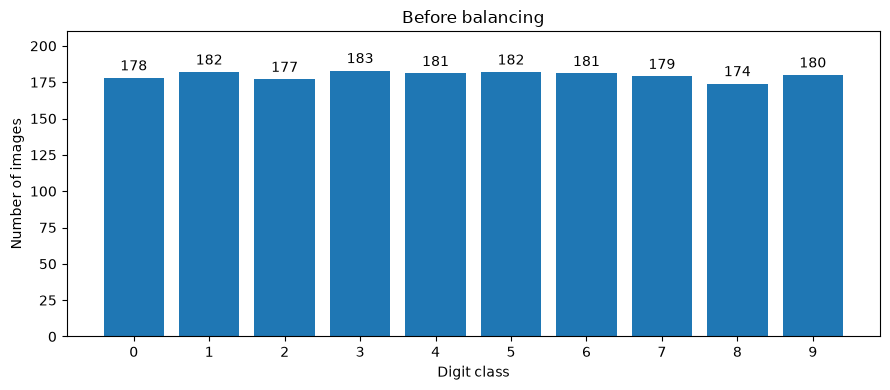

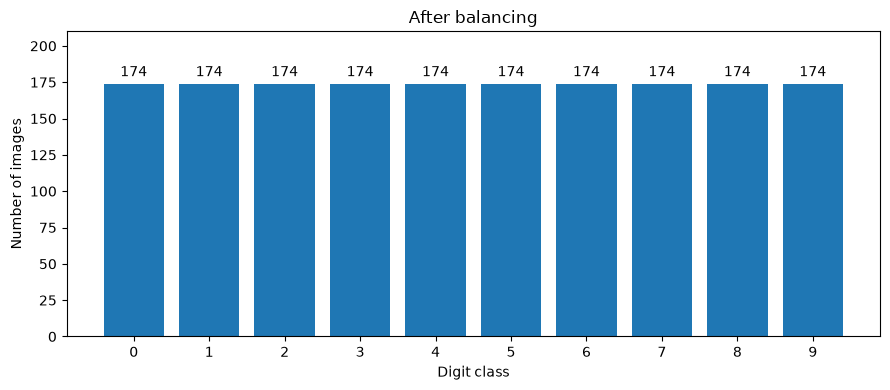

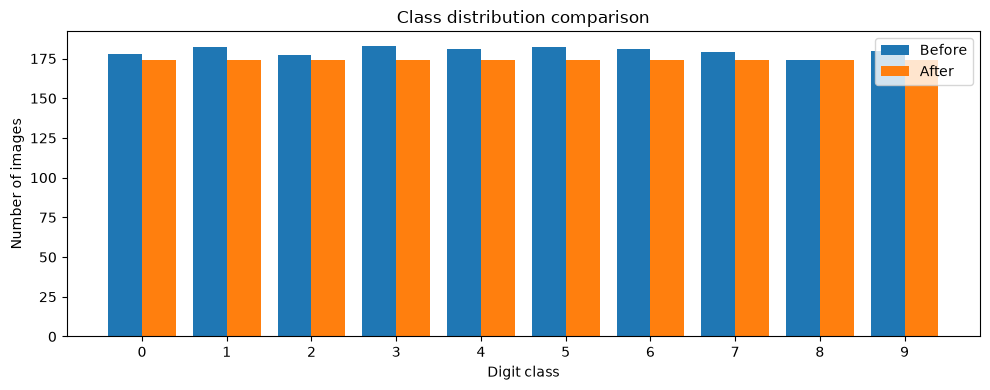

SUCCESS: all 3 graphs generated!


In [3]:
# Импортируем библиотеки для построения графиков
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Папка для сохранения графиков
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Строим графики до и после балансировки
for title, df, filename in [
    ("Before balancing", original, "01_before.png"),
    ("After balancing", balanced, "02_after.png")
]:
    counts = df["target"].value_counts().sort_index()

    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(counts.index, counts.values)

    ax.bar_label(bars, padding=3)
    ax.set_title(title)
    ax.set_xlabel("Digit class")
    ax.set_ylabel("Number of images")
    ax.set_xticks(range(10))
    ax.set_ylim(0, 210)

    fig.tight_layout()
    fig.savefig(fig_dir / filename, dpi=200)
    plt.show()
    plt.close(fig)

# Сравниваем распределения на одном графике
before = original["target"].value_counts().sort_index()
after = balanced["target"].value_counts().sort_index()

x = np.arange(10)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, before.values, 0.4, label="Before")
ax.bar(x + 0.2, after.values, 0.4, label="After")

ax.set_xticks(x)
ax.set_xlabel("Digit class")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution comparison")
ax.legend()

fig.tight_layout()
fig.savefig(fig_dir / "03_comparison.png", dpi=200)
plt.show()
plt.close(fig)

print("SUCCESS: all 3 graphs generated!")

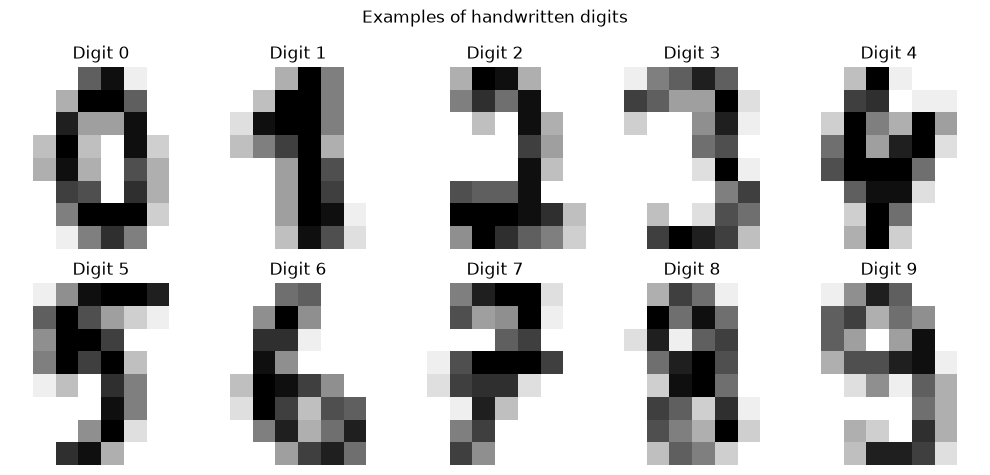

SUCCESS: digit examples saved!


In [4]:
# Выбираем столбцы с пикселями изображения
pixel_columns = [
    col for col in balanced.columns
    if col != "target"
]

# Создаём сетку из 10 изображений
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit, ax in enumerate(axes.flat):

    # Берём одно изображение соответствующей цифры
    sample = balanced.loc[
        balanced["target"] == digit,
        pixel_columns
    ].iloc[0]

    # Преобразуем 64 пикселя в матрицу 8x8
    image = sample.to_numpy().reshape(8, 8)

    # Отображаем изображение
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.suptitle("Examples of handwritten digits")
plt.tight_layout()

# Сохраняем изображения
plt.savefig(
    "../reports/figures/04_examples.png",
    dpi=200
)

plt.show()

print("SUCCESS: digit examples saved!")

## Проверка целостности данных

Для контроля целостности исходного и сбалансированного датасетов вычислим SHA256-хэши файлов.

Это позволяет убедиться, что данные не были случайно повреждены или незаметно изменены в процессе подготовки.

In [5]:
import hashlib
from pathlib import Path
import pandas as pd

def sha256sum(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

original_path = Path("../data/digits_original.csv")
balanced_path = Path("../data/digits.csv")

original_hash = sha256sum(original_path)
balanced_hash = sha256sum(balanced_path)

hash_df = pd.DataFrame({
    "file": [str(original_path), str(balanced_path)],
    "sha256": [original_hash, balanced_hash]
})

hash_df

,file,sha256
0,../data/digits_original.csv,59834b81e5525fe3152c7416217c7790c2213c0da554e8...
1,../data/digits.csv,4b55658bf1299c5e4bdce02ae154081e2694f74e22eca2...


In [6]:
from pathlib import Path

integrity_dir = Path("../integrity")
integrity_dir.mkdir(parents=True, exist_ok=True)

with open(integrity_dir / "hashes.txt", "w", encoding="utf-8") as f:
    f.write(f"digits_original.csv  {original_hash}\n")
    f.write(f"digits.csv           {balanced_hash}\n")

print("SUCCESS: hashes saved to ../integrity/hashes.txt")

SUCCESS: hashes saved to ../integrity/hashes.txt


### Вывод по проверке целостности

Для файлов `digits_original.csv` и `digits.csv` были вычислены SHA256-хэши.

Полученные значения сохранены в файл `integrity/hashes.txt`.

Это подтверждает, что для дальнейшей работы можно однозначно идентифицировать использованные версии датасета и контролировать возможные изменения файлов.

## Проверка защищённости окружения

В ходе лабораторной работы было подготовлено окружение для анализа данных и машинного обучения.

Проверены следующие компоненты:

- Python 3.12.3
- JupyterLab
- SSH-доступ
- Docker
- pip-audit для проверки уязвимостей Python-пакетов

Результат проверки показал, что известных уязвимостей в установленных Python-зависимостях не обнаружено.

In [9]:
audit_path = Path("../reports/pip_audit.txt")

if audit_path.exists():
    with open(audit_path, "r", encoding="utf-8") as f:
        audit_text = f.read()
    print(audit_text)
else:
    print("pip_audit.txt not found")

No known vulnerabilities found



## Мини-модель угроз ML-проекта

### Цель анализа

Определить основные угрозы безопасности Linux-окружения,
SSH-сервера, Git-репозитория и датасета, используемого
для обучения модели распознавания рукописных цифр.

| Актив | Угроза | Возможное последствие | Контрмера | Статус |
|---|---|---|---|---|
| SSH-сервер | Подбор пароля и несанкционированный вход | Получение доступа к серверу | SSH-ключ ED25519, запрет root, UFW limit | Реализовано; парольный вход пока разрешён |
| Датасет Digits | Подмена или повреждение изображений | Некорректное обучение ML-модели | SHA256 и проверка целостности файлов | Реализовано; отдельное хранение эталона запланировано |
| Git-репозиторий | Утечка паролей и API-ключей | Компрометация учётных записей | .gitignore и внешнее хранилище секретов | Запланировано |
| Python-библиотеки | Использование зависимостей с известными уязвимостями | Выполнение вредоносного кода или компрометация окружения | pip-audit, фиксация версий в requirements.txt | Реализовано; регулярный аудит запланирован |
| Сетевые службы | Эксплуатация ненужных открытых сервисов | Увеличение поверхности атаки | UFW, проверка ss -tulpn, отключение ненужных служб | UFW и анализ реализованы; отключение служб запланировано |

### Анализ реализованных мер защиты

1. SSH-сервер настроен на использование ключей ED25519.
   Вход пользователя root через SSH запрещён.
   Firewall UFW ограничивает частые подключения к SSH.

2. Для исходного и сбалансированного датасетов вычислены
   SHA256-хэши. Сравнение с сохранёнными значениями
   позволяет обнаруживать изменения файлов.

3. Выполнена проверка Python-зависимостей через pip-audit.
   На момент проверки известных уязвимостей не обнаружено.

4. Настроена сетевая защита UFW с запретом входящих
   подключений по умолчанию.

### Меры, требующие дальнейшей реализации

- Создание и проверка файла .gitignore.
- Хранение эталонных SHA256 отдельно от датасета.
- Отключение ненужных сетевых служб.
- Усиление парольной защиты SSH и учётных записей.
- Регулярная повторная проверка зависимостей.

### Вывод

Разработана мини-модель угроз, включающая пять основных
угроз безопасности системы машинного обучения.

Для каждой угрозы определены защищаемый актив,
возможные последствия, контрмеры и статус реализации.

Выполненные меры уменьшают поверхность атаки и позволяют
контролировать целостность данных, однако не исключают
все возможные угрозы.

In [10]:
cd ~/ml-project

/home/mluser/ml-project


cat > .gitignore <<'EOF'
.venv/
__pycache__/
.ipynb_checkpoints/
.env
.env.*
*.pyc
models/*.pkl
models/*.joblib
EOF